<a href="https://colab.research.google.com/github/saikiran-shriram/ml-notebooks/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# Features: [size_sqft, num_bedrooms, age_years]
X = np.array([
    [2104, 5, 45],
    [1416, 3, 40],
    [1534, 3, 30],
    [852,  2, 36],
    [1940, 4, 22]
])

y = np.array([460, 232, 315, 178, 400])

In [9]:
def sigmoid(z):
   return 1 / (1 + np.exp(-z))
def predict(X, w, b):
  z = np.dot(X, w) + b
  return sigmoid(z)


In [10]:
def compute_cost(X, y, w, b):
    m = X.shape[0]

    f_wb = predict(X, w, b)

    cost = -(1/m) * np.sum(
        y * np.log(f_wb + 1e-15)
        + (1 - y) * np.log(1 - f_wb + 1e-15)
    )

    return cost

In [11]:
def compute_gradient(X, y, w, b):
    m = X.shape[0]

    f_wb = predict(X, w, b)
    error = f_wb - y

    dj_dw = (1/m) * np.dot(X.T, error)
    dj_db = (1/m) * np.sum(error)

    return dj_dw, dj_db

In [12]:
def gradient_descent(X, y, w, b, alpha, iterations):

    for i in range(iterations):

        dj_dw, dj_db = compute_gradient(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i % 100 == 0:
            cost = compute_cost(X, y, w, b)
            print(f"Iteration {i}: Cost = {cost}")

    return w, b

In [13]:
w = np.zeros(X.shape[1])
b = 0
w, b = gradient_descent(
    X, y, w, b,
    alpha=0.001,
    iterations=1000
)

Iteration 0: Cost = -10914.253340791778
Iteration 100: Cost = -10914.253340791778
Iteration 200: Cost = -10914.253340791778
Iteration 300: Cost = -10914.253340791778
Iteration 400: Cost = -10914.253340791778
Iteration 500: Cost = -10914.253340791778
Iteration 600: Cost = -10914.253340791778
Iteration 700: Cost = -10914.253340791778
Iteration 800: Cost = -10914.253340791778
Iteration 900: Cost = -10914.253340791778


In [14]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

w = np.zeros(X_train.shape[1])
b = 0

w, b = gradient_descent(
    X_train, y_train, w, b,
    alpha=0.1,
    iterations=1000
)


Iteration 0: Cost = 0.6816982100647702
Iteration 100: Cost = 0.40913272639023024
Iteration 200: Cost = 0.3823572338186012
Iteration 300: Cost = 0.3748676263748243
Iteration 400: Cost = 0.3720901372920234
Iteration 500: Cost = 0.3709160453486708
Iteration 600: Cost = 0.37038205356771825
Iteration 700: Cost = 0.37012803971682806
Iteration 800: Cost = 0.37000364536405694
Iteration 900: Cost = 0.36994152943193614


Accuracy: 0.875
Confusion Matrix:
 [[18  5]
 [ 0 17]]


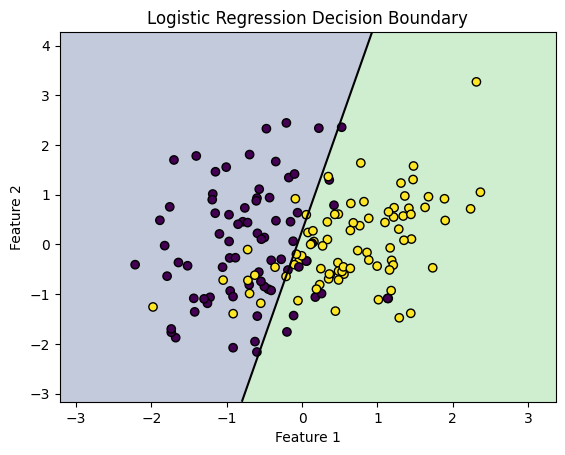

In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_prob = predict(X_test, w, b)
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Create a grid of points
x1_min, x1_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
x2_min, x2_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

# Predict for every point in the grid
grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = predict(grid, w, b).reshape(xx1.shape)

# Plot
plt.contourf(xx1, xx2, probs, levels=[0, 0.5, 1], alpha=0.3)
plt.contour(xx1, xx2, probs, levels=[0.5], colors="black")

plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train, edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Decision Boundary")
plt.show()